In [1]:
pip install coolProp

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [2]:
import CoolProp.CoolProp as CP
import numpy as np
import matplotlib.pyplot as plt

R_univ = 8.314       # J/mol·K
sb     = 5.67e-8     # W/m²·K⁴
g      = 9.81        # m/s²
in_m   = 0.0254      # inches → metres
in2_m2 = in_m**2

AR, H2O, H2, CO = 0, 1, 2, 3
M_sp = np.array([0.03995, 0.018016, 0.002016, 0.028010])  # kg/mol
M_C  = 0.012011

# Molar Cv  [J/mol·K]  Ar:3/2 R  H2O:4R(high-T)  H2,CO:5/2 R
Cv_sp = np.array([1.5, 4.0, 2.5, 2.5]) * R_univ
# Molar Cp = Cv + R  (ideal gas, used for open-system enthalpy flows)
Cp_sp = Cv_sp + R_univ


In [3]:
def CircPipeFF(Re, D_h, rough=1e-5):
    if Re < 2300:
        return 64.0 / Re
    return (-2*np.log10(2*rough/(7.54*D_h)
                        - 5.02/Re*np.log10(2*rough/(7.54*D_h)+13/Re)))**-2

def film_boil_h(T_gr, T_sat, P, eps=0.8):
    """Bromley film boiling HTC + radiation correction [W/m²·K]."""
    dT  = max(T_gr - T_sat, 1.0)
    k_v = CP.PropsSI('L','T',T_sat+1,'P',P,'Water')
    rv  = CP.PropsSI('D','T',T_sat+1,'P',P,'Water')
    rl  = CP.PropsSI('D','T',T_sat-1,'P',P,'Water')
    nul = CP.PropsSI('V','T',T_sat-1,'P',P,'Water')
    sig = CP.PropsSI('I','T',T_sat,'Q',0.99,'Water')
    hfg = (CP.PropsSI('H','T',T_sat+1,'P',P,'Water')
           - CP.PropsSI('H','T',T_sat-1,'P',P,'Water'))
    dhv = (CP.PropsSI('H','T',T_gr,'P',P,'Water')
           - CP.PropsSI('H','T',T_sat+1,'P',P,'Water'))
    hc  = 0.425*(k_v**3*rv*g*(rl-rv)*(hfg+0.4*dhv)
                 / (nul*rl*dT*(sig/(g*(rl-rv)))**0.5))**0.25
    hr  = eps*sb*(T_gr**4 - T_sat**4)/dT
    h   = 100.0
    for _ in range(80):
        hp = h
        h  = (hc**(4/3) + hr*h**(1/3))**0.75
        if abs(h-hp) < 0.1: break
    return h

def nucleate_boil_h(T_gr, T_sat, P, C_sf=0.006, n_pr=1.0):
    """Rohsenow nucleate boiling HTC [W/m²·K].  C_sf=0.006 for rough graphite."""
    dT  = max(T_gr - T_sat, 0.5)
    mul = CP.PropsSI('V','T',T_sat-1,'P',P,'Water')
    cpl = CP.PropsSI('C','T',T_sat-1,'P',P,'Water')
    Prl = CP.PropsSI('Prandtl','T',T_sat-1,'P',P,'Water')
    rl  = CP.PropsSI('D','T',T_sat-1,'P',P,'Water')
    rv  = CP.PropsSI('D','T',T_sat+1,'P',P,'Water')
    sig = CP.PropsSI('I','T',T_sat,'Q',0.99,'Water')
    hfg = (CP.PropsSI('H','T',T_sat+1,'P',P,'Water')
           - CP.PropsSI('H','T',T_sat-1,'P',P,'Water'))
    q   = mul*hfg*(g*(rl-rv)/sig)**0.5*(cpl*dT/(C_sf*hfg*Prl**n_pr))**3
    return q / dT


In [6]:
def simulate_mtr(m_rate_gpm,
                 t_end=240, n=24000,
                 T_gr_init_K=2073.0, m_gr_kg=18.0, cp_gr=2000.0,
                 rho_graphite=1800.0,
                 L_box_in=14.0, V_vessel=1.0,
                 T_w_init=293.0, P_init=1e5, P_atm=1e5,
                 eps_gr=0.8,
                 water_gas_rxn=True, T_wgr_K=1073.0, f_wgr=1.0,
                 dT_Leidenfrost=200.0,
                 T_hot_init_K=None,
                 T_cold_init_K=313.0,
                 P_relief_Pa=1.2e5, P_burst_Pa=1.7e5, P_burst2_Pa=2.67e5,
                 C_d_relief=0.5, C_d_burst=0.9,
                 d_relief_in=0.25, d_burst_in=1.37, d_burst2_in=0.5,
                 N_reliefs=1, N_burst=2, N_burst2=1,
                 A_orifice_in2=36.0, C_d_orifice=0.6):

    if T_hot_init_K is None:
        T_hot_init_K = T_gr_init_K

    dt = t_end / n

    # ── Geometry ────────────────────────────────────────────────────────────
    L         = L_box_in * in_m
    V_box     = L**3
    V_gr      = m_gr_kg / rho_graphite
    V_hot     = max(V_box - V_gr, 0.005)
    V_cold    = max(V_vessel - V_box, 0.001)
    A_rh      = 5.0 * L**2            # 5 inner graphite faces → hot zone gas
    A_ori_eff = C_d_orifice * A_orifice_in2 * in2_m2  # effective orifice area [m²]

    A_relief = N_reliefs * np.pi*(d_relief_in*in_m)**2/4
    A_burst  = N_burst   * np.pi*(d_burst_in *in_m)**2/4
    A_burst2 = N_burst2  * np.pi*(d_burst2_in*in_m)**2/4

    # ── Initial conditions ──────────────────────────────────────────────────
    n_Ar_hot_init  = P_init * V_hot  / (R_univ * T_hot_init_K)
    n_Ar_cold_init = P_init * V_cold / (R_univ * T_cold_init_K)

    n_sp_hot  = np.zeros(4);  n_sp_hot[AR]  = n_Ar_hot_init
    n_sp_cold = np.zeros(4);  n_sp_cold[AR] = n_Ar_cold_init

    T_gr   = float(T_gr_init_K)
    T_hot  = float(T_hot_init_K)
    T_cold = float(T_cold_init_K)
    U_hot  = float((n_sp_hot  @ Cv_sp) * T_hot)
    U_cold = float((n_sp_cold @ Cv_sp) * T_cold)

    m_w      = 0.0
    m_gr     = float(m_gr_kg)
    is_burst = False;  is_burst2 = False
    m_rate   = m_rate_gpm * 3.9 / 60.0
    t_burst1 = None;   t_burst2  = None

    nout = n + 1
    t_out     = np.zeros(nout); P_hot_out = np.zeros(nout); P_out    = np.zeros(nout)
    Tgr_out   = np.zeros(nout); Thot_out  = np.zeros(nout); Tc_out   = np.zeros(nout)
    xH2_out   = np.zeros(nout); xCO_out   = np.zeros(nout); mw_out   = np.zeros(nout)
    mdotv_out = np.zeros(nout)

    P_hot_out[0] = P_init;  P_out[0] = P_init
    Tgr_out[0]   = T_gr;    Thot_out[0] = T_hot;  Tc_out[0] = T_cold

    for i in range(n):

        # ── Zone pressures (independent) ────────────────────────────────────
        P_hot_zone  = max(n_sp_hot.sum()  * R_univ * T_hot  / V_hot,  100.0)
        P_cold_zone = max(n_sp_cold.sum() * R_univ * T_cold / V_cold, 100.0)
        P = P_cold_zone   # cold zone pressure drives boiling / water properties

        # ── Boiling area ─────────────────────────────────────────────────────
        T_sat = CP.PropsSI('T', 'Q', 0, 'P', P, 'Water')
        rho_l = CP.PropsSI('D', 'T', max(T_sat - 1, 274), 'P', P, 'Water')
        h_w   = (m_w / rho_l) / (L**2)
        A_boil = L**2 + min(4.0 * L * h_w, 4.0 * L**2)

        # ── Boiling HTC ──────────────────────────────────────────────────────
        T_L = T_sat + dT_Leidenfrost
        if T_gr > T_L:
            h_b = film_boil_h(T_gr, T_sat, P, eps_gr)
        elif T_gr > T_sat + 30:
            h_f  = film_boil_h(T_gr, T_sat, P, eps_gr)
            h_n  = nucleate_boil_h(T_gr, T_sat, P)
            frac = (T_gr - T_sat - 30) / max(T_L - T_sat - 30, 1.0)
            h_b  = frac * h_f + (1 - frac) * h_n
        elif T_gr > T_sat:
            h_b = nucleate_boil_h(T_gr, T_sat, P)
        else:
            h_b = 0.0

        # ── Steam generation ─────────────────────────────────────────────────
        dh_w   = (CP.PropsSI('H', 'Q', 1, 'P', P, 'Water') -
                  CP.PropsSI('H', 'T', T_w_init, 'P', P, 'Water'))
        q_b    = h_b * A_boil * max(T_gr - T_sat, 0.0)
        rate_b = min(q_b / max(dh_w, 1.0), max(m_w, 0.0) / dt)

        # ── Water-gas reaction (C + H2O → CO + H2, ΔH = +131 kJ/mol) ───────
        if water_gas_rxn and T_gr > T_wgr_K and m_w > 1e-9:
            rate_wgr = f_wgr * rate_b
        else:
            rate_wgr = 0.0

        dn_H2O = (rate_b - rate_wgr) / M_sp[H2O]
        dn_H2  =  rate_wgr / M_sp[H2O]
        dn_CO  =  rate_wgr / M_sp[H2O]
        dm_C   =  rate_wgr / M_sp[H2O] * M_C
        Q_wgr  =  dn_H2 * 131e3

        # ── Hot zone — well-mixed transit model ──────────────────────────────
        # (a) Transit steam enters hot zone at T_sat
        n_sp_hot[H2O] += dn_H2O * dt
        U_hot += dn_H2O * dt * Cp_sp[H2O] * T_sat

        # (b) H2 and CO from WGR are generated inside the box → go to hot zone
        n_sp_hot[H2] += dn_H2 * dt
        n_sp_hot[CO] += dn_CO * dt
        U_hot += dn_H2 * dt * Cp_sp[H2] * T_gr
        U_hot += dn_CO * dt * Cp_sp[CO] * T_gr

        # (c) Q_rad heats the well-mixed hot zone gas; cap at T_gr
        Cv_hot    = float(n_sp_hot @ Cv_sp)
        T_hot_mix = U_hot / max(Cv_hot, 1e-30)
        Q_rad_max = max(eps_gr * sb * A_rh * (T_gr**4 - T_hot_mix**4), 0.0)
        Q_rad_cap = max((Cv_hot * T_gr - U_hot) / dt, 0.0)
        Q_rad_hot = min(Q_rad_max, Q_rad_cap)
        U_hot += Q_rad_hot * dt
        U_hot  = min(U_hot, Cv_hot * T_gr)

        # (d) Well-mixed T_hot
        T_hot = max(U_hot / max(Cv_hot, 1e-30), T_sat)

        # (e) Transit steam exits at T_hot → cold zone
        n_sp_hot[H2O] -= dn_H2O * dt
        U_hot  -= dn_H2O * dt * Cp_sp[H2O] * T_hot
        n_sp_cold[H2O] += dn_H2O * dt
        U_cold += dn_H2O * dt * Cp_sp[H2O] * T_hot

        # (f) T_hot after steam exits
        T_hot = max(U_hot / max(n_sp_hot @ Cv_sp, 1e-30), 273.0)

        # ── Graphite energy balance ───────────────────────────────────────────
        Q_gr_loss = rate_b * dh_w + Q_wgr + Q_rad_hot
        T_gr -= Q_gr_loss * dt / max(m_gr * cp_gr, 1.0)
        m_gr -= dm_C * dt;  m_gr = max(m_gr, 0.0)
        T_gr  = max(T_gr, 273.0)

        # ── Liquid water ──────────────────────────────────────────────────────
        m_w = max(m_w + m_rate * dt - rate_b * dt, 0.0)

        # ── Orifice flow: hot zone ↔ cold zone (driven by ΔP) ────────────────
        P_hot_zone  = max(n_sp_hot.sum()  * R_univ * T_hot  / V_hot,  100.0)
        P_cold_zone = max(n_sp_cold.sum() * R_univ * T_cold / V_cold, 100.0)
        dP_zones = P_hot_zone - P_cold_zone
        n_hot_tot  = n_sp_hot.sum()
        n_cold_tot = n_sp_cold.sum()

        if dP_zones > 0 and n_hot_tot > 0:
            # hot → cold
            Mw_hot  = float(n_sp_hot @ M_sp) / max(n_hot_tot, 1e-30)
            rho_hot = n_hot_tot * Mw_hot / V_hot
            Q_ori   = A_ori_eff * np.sqrt(2.0 * dP_zones / max(rho_hot, 1e-8))
            # Energy-consistent equilibration cap: prevents oscillation when orifice
            # can equilibrate faster than dt. Derived from d(P_hot)/d(dn) with enthalpy flow:
            # dn_eq = ΔP / (γ_hot · R · T_hot · (1/V_hot + 1/V_cold))
            Cv_h_avg = float(n_sp_hot @ Cv_sp) / max(n_hot_tot, 1e-30)
            gamma_h  = (Cv_h_avg + R_univ) / Cv_h_avg
            n_eq     = max(dP_zones / (gamma_h * R_univ * T_hot * (1.0/V_hot + 1.0/V_cold)), 0.0)
            n_xfer   = min(Q_ori * rho_hot / Mw_hot * dt, n_eq)
            f_hot    = n_sp_hot / max(n_hot_tot, 1e-30)
            dn_xfer  = np.minimum(f_hot * n_xfer, n_sp_hot)
            U_hot   -= float(dn_xfer @ Cp_sp) * T_hot
            U_cold  += float(dn_xfer @ Cp_sp) * T_hot
            n_sp_hot  -= dn_xfer
            n_sp_cold += dn_xfer
        elif dP_zones < 0 and n_cold_tot > 0:
            # backflow: cold → hot
            Mw_cold_z  = float(n_sp_cold @ M_sp) / max(n_cold_tot, 1e-30)
            rho_cold_z = n_cold_tot * Mw_cold_z / V_cold
            Q_back     = A_ori_eff * np.sqrt(2.0 * (-dP_zones) / max(rho_cold_z, 1e-8))
            Cv_c_avg  = float(n_sp_cold @ Cv_sp) / max(n_cold_tot, 1e-30)
            gamma_c   = (Cv_c_avg + R_univ) / Cv_c_avg
            n_eq_back = max((-dP_zones) / (gamma_c * R_univ * T_cold * (1.0/V_cold + 1.0/V_hot)), 0.0)
            n_back    = min(Q_back * rho_cold_z / Mw_cold_z * dt, n_eq_back)
            f_cold_z  = n_sp_cold / max(n_cold_tot, 1e-30)
            dn_back   = np.minimum(f_cold_z * n_back, n_sp_cold)
            U_cold   -= float(dn_back @ Cp_sp) * T_cold
            U_hot    += float(dn_back @ Cp_sp) * T_cold
            n_sp_cold -= dn_back
            n_sp_hot  += dn_back

        # ── Recompute temperatures after orifice exchange ────────────────────
        T_hot  = max(U_hot  / max(n_sp_hot  @ Cv_sp, 1e-30), 273.0)
        T_cold = max(U_cold / max(n_sp_cold @ Cv_sp, 1e-30), 273.0)

        # ── Venting from cold zone ────────────────────────────────────────────
        P_cold_zone = max(n_sp_cold.sum() * R_univ * T_cold / V_cold, 100.0)
        if P_cold_zone > P_burst_Pa  and not is_burst:  is_burst  = True;  t_burst1 = (i+1)*dt
        if P_cold_zone > P_burst2_Pa and not is_burst2: is_burst2 = True;  t_burst2 = (i+1)*dt

        n_cold_tot = n_sp_cold.sum()
        Mw_cold    = float(n_sp_cold @ M_sp) / max(n_cold_tot, 1e-30)
        rho_cold   = n_cold_tot * Mw_cold / V_cold

        mdot_v = 0.0
        if P_cold_zone > P_relief_Pa:
            dP = max(P_cold_zone - P_atm, 0.0)
            mdot_v += C_d_relief * A_relief * np.sqrt(2 * rho_cold * dP)
        for A_b, is_b in [(A_burst, is_burst), (A_burst2, is_burst2)]:
            if is_b and P_cold_zone > P_atm:
                dP = max(P_cold_zone - P_atm, 0.0)
                mdot_v += C_d_burst * A_b * np.sqrt(2 * rho_cold * dP)

        if mdot_v > 0 and n_cold_tot > 0:
            n_orifice    = mdot_v * dt / Mw_cold
            n_max_remove = max(n_cold_tot * (1.0 - P_atm / max(P_cold_zone, P_atm)), 0.0)
            dn_v_total   = min(n_orifice, n_max_remove)
            f_cold = n_sp_cold / max(n_cold_tot, 1e-30)
            dn_v   = np.minimum(f_cold * dn_v_total, n_sp_cold)
            U_cold -= float(dn_v @ Cp_sp) * T_cold
            n_sp_cold -= dn_v
            if n_sp_cold.sum() > 0:
                T_cold = max(U_cold / max(n_sp_cold @ Cv_sp, 1e-30), 273.0)

        # ── Atmospheric backflow through open burst disks (bidirectional) ────
        # Once ruptured, burst disks are open holes — allow air inflow when
        # P_cold drops below P_atm (models real bidirectional behavior).
        P_cold_zone = max(n_sp_cold.sum() * R_univ * T_cold / V_cold, 100.0)
        if (is_burst or is_burst2) and P_cold_zone < P_atm:
            A_open  = (A_burst if is_burst else 0.0) + (A_burst2 if is_burst2 else 0.0)
            dP_in   = P_atm - P_cold_zone
            rho_in  = P_atm * M_sp[AR] / (R_univ * max(T_cold, 273.0))
            mdot_in = C_d_burst * A_open * np.sqrt(2.0 * rho_in * dP_in)
            n_in    = min(mdot_in * dt / M_sp[AR],
                         max(P_atm * V_cold / (R_univ * T_cold) - n_sp_cold.sum(), 0.0))
            n_sp_cold[AR] += n_in
            U_cold        += n_in * Cp_sp[AR] * T_cold
            T_cold = max(U_cold / max(n_sp_cold @ Cv_sp, 1e-30), 273.0)
            P_cold_zone = max(n_sp_cold.sum() * R_univ * T_cold / V_cold, 100.0)

        mdotv_out[i+1] = mdot_v

        # ── Record ────────────────────────────────────────────────────────────
        t_out[i+1]      = (i+1) * dt
        P_hot_out[i+1]  = max(n_sp_hot.sum()  * R_univ * T_hot  / V_hot,  100.0)
        P_out[i+1]      = max(n_sp_cold.sum() * R_univ * T_cold / V_cold, 100.0)
        Tgr_out[i+1]    = T_gr
        Thot_out[i+1]   = T_hot
        Tc_out[i+1]     = T_cold
        n_all           = n_sp_hot.sum() + n_sp_cold.sum()
        xH2_out[i+1]    = (n_sp_hot[H2] + n_sp_cold[H2]) / max(n_all, 1e-30)
        xCO_out[i+1]    = (n_sp_hot[CO] + n_sp_cold[CO]) / max(n_all, 1e-30)
        mw_out[i+1]     = m_w

    return t_out, P_hot_out, P_out, Tgr_out, Thot_out, Tc_out, xH2_out, xCO_out, mw_out, mdotv_out, t_burst1, t_burst2


0.001 GPM  peak P=2.940 psi  peak H2=2.5%  Tgr_final=1796C  Thot_final=1795C
0.003 GPM  peak P=4.515 psi  peak H2=8.7%  Tgr_final=1787C  Thot_final=1785C
0.010 GPM  peak P=10.281 psi  peak H2=20.4%  Tgr_final=1757C  Thot_final=1749C BD1@39.2s
0.030 GPM  peak P=10.261 psi  peak H2=25.9%  Tgr_final=1671C  Thot_final=1648C BD1@10.0s
0.100 GPM  peak P=10.274 psi  peak H2=37.2%  Tgr_final=1360C  Thot_final=1307C BD1@2.9s
0.300 GPM  peak P=10.262 psi  peak H2=50.0%  Tgr_final=929C  Thot_final=905C BD1@1.0s
1.000 GPM  peak P=9.898 psi  peak H2=50.0%  Tgr_final=791C  Thot_final=736C BD1@0.5s
3.000 GPM  peak P=9.944 psi  peak H2=50.0%  Tgr_final=690C  Thot_final=573C BD1@0.5s
10.000 GPM  peak P=10.114 psi  peak H2=50.0%  Tgr_final=618C  Thot_final=518C BD1@0.5s


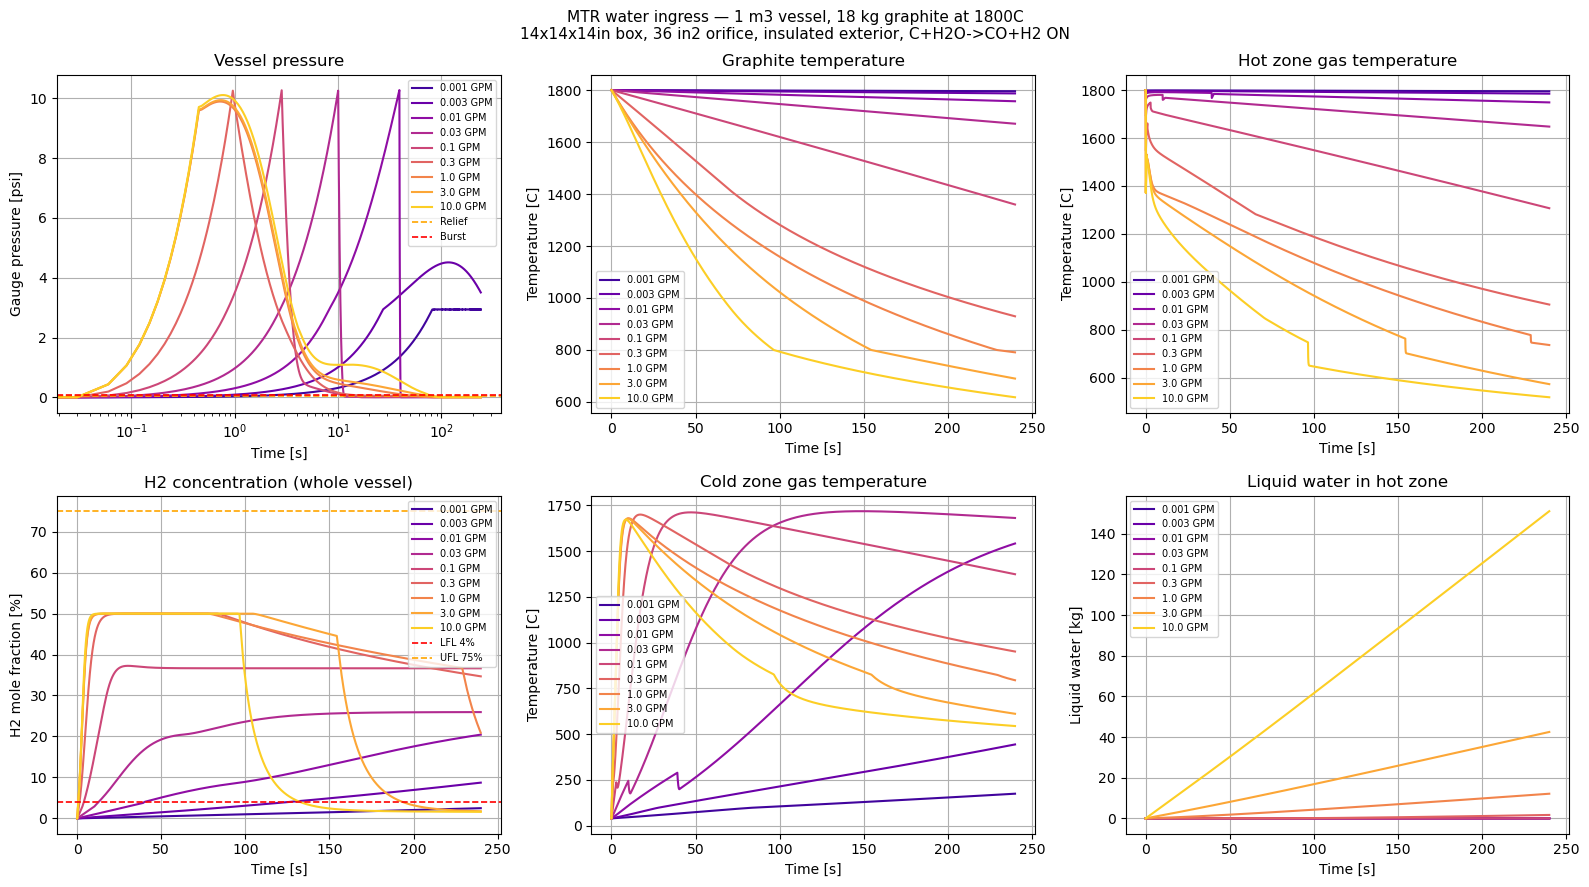

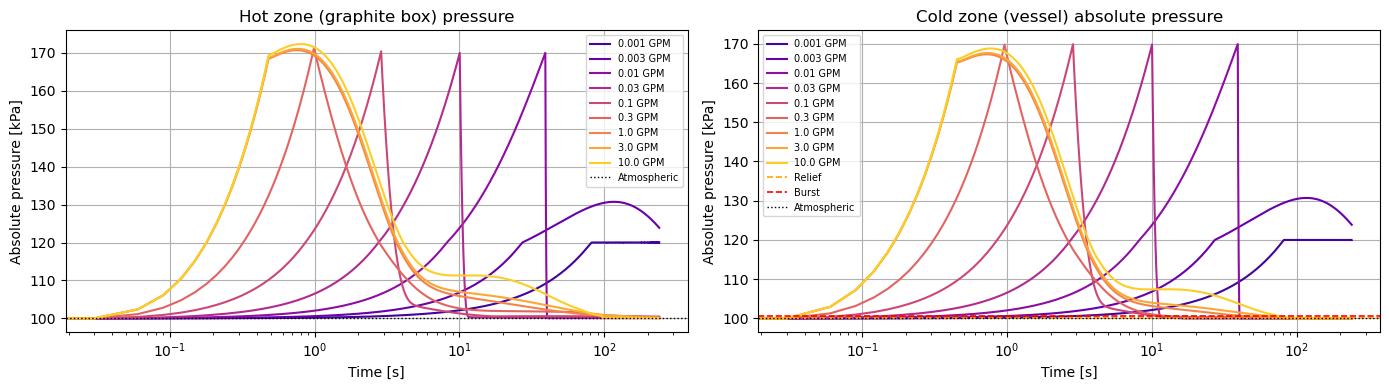

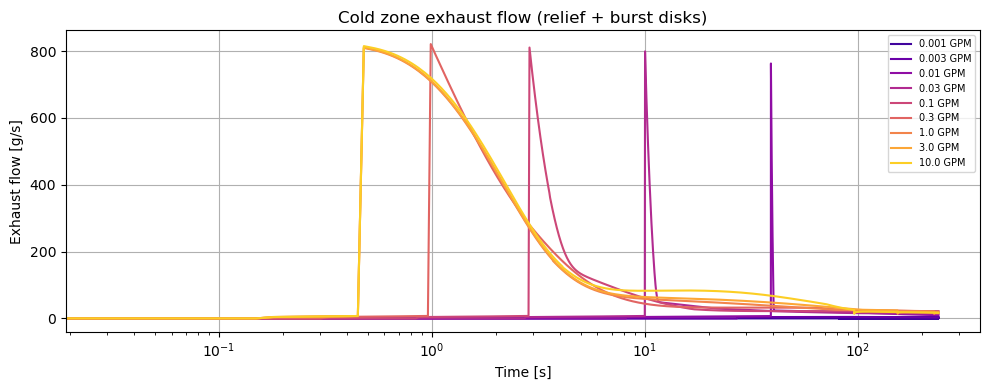

In [7]:
m_w_list_gpm = [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0]
colors = plt.cm.plasma(np.linspace(0.1, 0.9, len(m_w_list_gpm)))

results = {}
for gpm, col in zip(m_w_list_gpm, colors):
    t, P_hot, P, Tgr, Thot, Tc, xH2, xCO, mw, mdot_v, t_burst1, t_burst2 = simulate_mtr(
        gpm, t_end=240, n=8000,
        T_hot_init_K=None,
        T_cold_init_K=313.0)
    results[gpm] = dict(t=t, P_hot=P_hot, P=P, Tgr=Tgr, Thot=Thot, Tc=Tc,
                        xH2=xH2, xCO=xCO, mw=mw, col=col, mdot_v=mdot_v,
                        t_burst1=t_burst1, t_burst2=t_burst2)
    P_gauge_peak = (P.max() - 1e5) * 14.7 / 1e5
    b1_str = f" BD1@{t_burst1:.1f}s" if t_burst1 is not None else ""
    b2_str = f" BD2@{t_burst2:.1f}s" if t_burst2 is not None else ""
    print(f"{gpm:.3f} GPM  peak P={P_gauge_peak:.3f} psi  "
          f"peak H2={xH2.max()*100:.1f}%  Tgr_final={Tgr[-1]-273:.0f}C  "
          f"Thot_final={Thot[-1]-273:.0f}C{b1_str}{b2_str}")

P_atm = 1e5
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

ax = axes[0, 0]
for gpm, r in results.items():
    ax.semilogx(r['t'], (r['P'] - P_atm) * 14.7 / P_atm, color=r['col'], label=f'{gpm} GPM')
ax.axhline((1.002e5-P_atm)*14.7/P_atm, color='orange', ls='--', lw=1.2, label='Relief')
ax.axhline((1.005e5-P_atm)*14.7/P_atm, color='red',    ls='--', lw=1.2, label='Burst')
ax.set_xlabel('Time [s]'); ax.set_ylabel('Gauge pressure [psi]')
ax.set_title('Vessel pressure'); ax.legend(fontsize=7); ax.grid(True)

ax = axes[0, 1]
for gpm, r in results.items():
    ax.plot(r['t'], r['Tgr'] - 273, color=r['col'], label=f'{gpm} GPM')
ax.set_xlabel('Time [s]'); ax.set_ylabel('Temperature [C]')
ax.set_title('Graphite temperature'); ax.legend(fontsize=7); ax.grid(True)

ax = axes[0, 2]
for gpm, r in results.items():
    ax.plot(r['t'], r['Thot'] - 273, color=r['col'], label=f'{gpm} GPM')
ax.set_xlabel('Time [s]'); ax.set_ylabel('Temperature [C]')
ax.set_title('Hot zone gas temperature'); ax.legend(fontsize=7); ax.grid(True)

ax = axes[1, 0]
for gpm, r in results.items():
    ax.plot(r['t'], r['xH2'] * 100, color=r['col'], label=f'{gpm} GPM')
ax.axhline(4,  color='red',    ls='--', lw=1.2, label='LFL 4%')
ax.axhline(75, color='orange', ls='--', lw=1.2, label='UFL 75%')
ax.set_xlabel('Time [s]'); ax.set_ylabel('H2 mole fraction [%]')
ax.set_title('H2 concentration (whole vessel)'); ax.legend(fontsize=7); ax.grid(True)

ax = axes[1, 1]
for gpm, r in results.items():
    ax.plot(r['t'], r['Tc'] - 273, color=r['col'], label=f'{gpm} GPM')
ax.set_xlabel('Time [s]'); ax.set_ylabel('Temperature [C]')
ax.set_title('Cold zone gas temperature'); ax.legend(fontsize=7); ax.grid(True)

ax = axes[1, 2]
for gpm, r in results.items():
    ax.plot(r['t'], r['mw'], color=r['col'], label=f'{gpm} GPM')
ax.set_xlabel('Time [s]'); ax.set_ylabel('Liquid water [kg]')
ax.set_title('Liquid water in hot zone'); ax.legend(fontsize=7); ax.grid(True)

plt.suptitle('MTR water ingress — 1 m3 vessel, 18 kg graphite at 1800C\n'
             '14x14x14in box, 36 in2 orifice, insulated exterior, C+H2O->CO+H2 ON',
             fontsize=11)
plt.tight_layout()
plt.show()
fig2, (ax2a, ax2b) = plt.subplots(1, 2, figsize=(14, 4))
for gpm, r in results.items():
    ax2a.semilogx(r['t'], r['P_hot'] / 1e3, color=r['col'], label=f'{gpm} GPM')
ax2a.axhline(P_atm/1e3, color='black', ls=':', lw=1.0, label='Atmospheric')
ax2a.set_xlabel('Time [s]'); ax2a.set_ylabel('Absolute pressure [kPa]')
ax2a.set_title('Hot zone (graphite box) pressure'); ax2a.legend(fontsize=7); ax2a.grid(True)
for gpm, r in results.items():
    ax2b.semilogx(r['t'], r['P'] / 1e3, color=r['col'], label=f'{gpm} GPM')
ax2b.axhline(1.002e5/1e3, color='orange', ls='--', lw=1.2, label='Relief')
ax2b.axhline(1.005e5/1e3, color='red',    ls='--', lw=1.2, label='Burst')
ax2b.axhline(P_atm/1e3,   color='black',  ls=':',  lw=1.0, label='Atmospheric')
ax2b.set_xlabel('Time [s]'); ax2b.set_ylabel('Absolute pressure [kPa]')
ax2b.set_title('Cold zone (vessel) absolute pressure'); ax2b.legend(fontsize=7); ax2b.grid(True)
plt.tight_layout()
plt.show()

fig3, ax3 = plt.subplots(figsize=(10, 4))
for gpm, r in results.items():
    ax3.semilogx(r['t'], r['mdot_v'] * 1000, color=r['col'], label=f'{gpm} GPM')
ax3.set_xlabel('Time [s]')
ax3.set_ylabel('Exhaust flow [g/s]')
ax3.set_title('Cold zone exhaust flow (relief + burst disks)')
ax3.legend(fontsize=7); ax3.grid(True)
plt.tight_layout()
plt.show()
